# 05 Passes as football

PLAN.md step 6, from held-out XGBoost predictions only. Logic in `evaluate.held_out_passes`, `surprising_passes`, `completion_above_expected` and `viz.plot_passes`.

In [1]:
import pandas as pd
from IPython.display import Image
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"
read = lambda name, **kw: pd.read_csv(RESULTS / f"{name}.csv", **kw)

## Two passes on the pitch
Left: the riskiest completed pass in the opponents' half whose intended target was the real receiver. Right: the pass the model was most sure of that was lost. Solid line = the pass the model scored (passer to intended target); dashed arrow = where the ball actually went (events, shown for context only, never a model input).

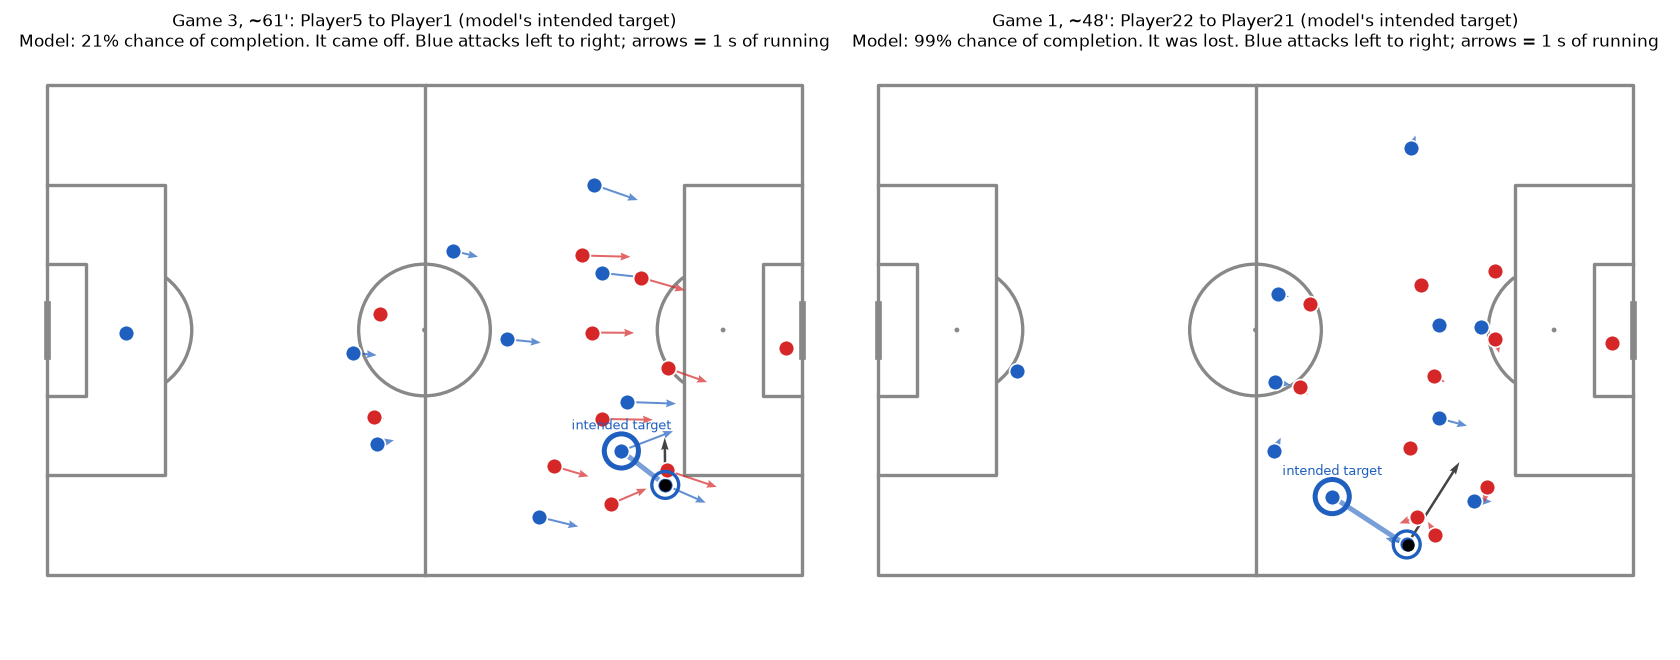

In [2]:
Image(RESULTS / "figures" / "pass_stories.png")

## 10 riskiest completed passes
`target_player` vs `receiver` shows how often the intended-target model picked someone else.

In [3]:
risky = read("step6_riskiest_completed")
print(f"intended target = receiver on {(risky.target_player == risky.receiver).mean():.0%} of these")
risky

intended target = receiver on 20% of these


,match_id,period,approx_minute,passer,target_player,receiver,p_complete,pass_length,target_nearest_opp,passer_nearest_opp,lane_opps,start_x,event_id
0,1,1,35.736,Player7,Player9,Player8,0.084,16.331,2.503,4.335,2,49.035,657
1,3,2,88.479,Player14,Player5,Player6,0.124,15.889,4.301,1.498,2,46.523,3355
2,3,1,17.883,Player11,Player6,Player3,0.133,23.382,9.637,5.534,0,-46.365,688
3,2,2,74.475,Player18,Player26,Player24,0.138,10.113,1.268,3.415,2,46.380,1663
4,3,2,94.961,Player17,Player11,Player10,0.142,8.259,7.600,2.204,0,-46.747,3589
5,3,2,58.573,Player24,Player28,Player26,0.169,12.283,9.276,2.744,0,-42.562,2277
6,3,2,53.025,Player21,Player26,Player24,0.181,18.335,8.913,1.885,1,-38.490,2021
7,3,1,8.176,Player28,Player19,Player23,0.194,7.359,4.817,3.448,1,-34.296,297
8,1,1,23.097,Player3,Player11,Player11,0.207,4.002,5.600,1.598,0,-46.905,461
9,3,2,60.627,Player5,Player1,Player1,0.207,7.711,5.196,2.051,1,33.462,2329


## 10 safest failed passes
All have a wide-open intended target (`target_nearest_opp` 8-20 m) and an empty lane: many are probably passes aimed at someone else, i.e. intended-target errors rather than model errors.

In [4]:
read("step6_safest_failed")

,match_id,period,approx_minute,passer,target_player,receiver,p_complete,pass_length,target_nearest_opp,passer_nearest_opp,lane_opps,start_x,event_id
0,1,2,48.361,Player22,Player21,NaN,0.987,12.311,12.152,4.108,0,21.019,902
1,3,1,23.039,Player3,Player4,NaN,0.986,23.403,17.422,3.763,0,-21.773,864
2,1,2,75.593,Player3,Player11,NaN,0.983,15.123,19.876,7.297,0,-28.342,1358
3,1,1,46.020,Player20,Player15,NaN,0.983,18.263,17.723,10.796,0,-9.539,876
4,1,1,16.065,Player2,Player11,NaN,0.982,14.559,18.676,6.167,0,-36.604,333
5,3,2,66.777,Player12,Player1,NaN,0.981,24.306,17.657,5.457,0,-14.868,2529
6,1,2,76.871,Player19,Player20,NaN,0.981,7.818,12.973,5.334,0,25.110,1395
7,1,2,48.126,Player6,Player2,NaN,0.981,7.550,13.807,7.455,0,-11.818,894
8,1,2,70.491,Player16,Player19,NaN,0.977,6.680,8.218,10.289,0,-7.679,1286
9,3,2,80.868,Player33,Player34,NaN,0.975,10.379,11.747,11.083,0,-10.745,3074


## Completion above expected (per player per match, >= 40 passes)
**Caveat:** a few dozen passes per player, so most differences are within ~2 se of zero. And match-level differences (match 1 completes 75%, match 2 82%) push whole teams up or down: this mixes player skill with match context the model never saw.

In [5]:
cae = read("step6_completion_above_expected", index_col=[0, 1])
cae.assign(beyond_2se=(cae.above_expected.abs() > 2 * cae.se))

passes  completion  expected  above_expected     se  \
match_id passer                                                          
3        Player25      40       0.875     0.744           0.131  0.060   
2        Player20      52       0.865     0.772           0.093  0.054   
         Player9       62       0.839     0.749           0.089  0.050   
         Player6       80       0.912     0.825           0.087  0.039   
         Player3       40       0.825     0.747           0.078  0.061   
         Player5       88       0.875     0.805           0.070  0.040   
         Player4       65       0.892     0.825           0.067  0.043   
3        Player24      73       0.904     0.838           0.066  0.038   
2        Player1       55       0.782     0.717           0.065  0.056   
1        Player5       40       0.850     0.788           0.062  0.060   
3        Player4       51       0.804     0.746           0.058  0.053   
2        Player7       64       0.828     0.771           0.057  0.048   
         Player15      64       0.781     0.727           0.054  0.049   
         Player21      58       0.862     0.811           0.051  0.048   
         Player18      52       0.808     0.761           0.046  0.053   
1        Player12      57       0.895     0.862           0.033  0.043   
2        Player8       55       0.800     0.773           0.027  0.051   
         Player2       41       0.829     0.812           0.017  0.053   
1        Player4       53       0.792     0.779           0.013  0.052   
3        Player2       40       0.850     0.851          -0.001  0.052   
1        Player3       45       0.800     0.804          -0.004  0.053   
3        Player3       66       0.848     0.853          -0.005  0.039   
         Player20      63       0.810     0.817          -0.008  0.043   
1        Player7       55       0.782     0.791          -0.009  0.049   
         Player6       44       0.841     0.852          -0.011  0.051   
3        Player6       64       0.797     0.810          -0.014  0.046   
         Player5       57       0.772     0.795          -0.023  0.050   
         Player21      54       0.741     0.765          -0.024  0.053   
         Player23      53       0.830     0.855          -0.025  0.046   
         Player1       73       0.740     0.765          -0.025  0.044   
2        Player16      59       0.847     0.877          -0.029  0.039   
3        Player22      52       0.769     0.799          -0.030  0.052   
1        Player21      74       0.838     0.869          -0.031  0.036   
3        Player19      55       0.818     0.853          -0.035  0.043   
         Player7       70       0.786     0.827          -0.041  0.043   
1        Player20      41       0.829     0.872          -0.043  0.048   
2        Player17      55       0.836     0.881          -0.045  0.038   
3        Player13      57       0.807     0.853          -0.046  0.045   
1        Player17      50       0.720     0.779          -0.059  0.051   
         Player8       47       0.660     0.725          -0.065  0.058   
         Player2       55       0.727     0.820          -0.093  0.046   
         Player16      47       0.766     0.893          -0.127  0.041   
         Player15      44       0.682     0.822          -0.140  0.054   
         Player19      52       0.654     0.834          -0.180  0.049   

                   beyond_2se  
match_id passer                
3        Player25        True  
2        Player20       False  
         Player9        False  
         Player6         True  
         Player3        False  
         Player5        False  
         Player4        False  
3        Player24       False  
2        Player1        False  
1        Player5        False  
3        Player4        False  
2        Player7        False  
         Player15       False  
         Player21       False  
         Player18       False  
1        Player12       False  
2        Player8        False  
      

In [6]:
cae.groupby(level="match_id")["above_expected"].mean().rename("mean above expected per match")

match_id
1   -0.046714
2    0.048467
3   -0.001467
Name: mean above expected per match, dtype: float64